# 01 — Delivery SLA Breach: EDA, Model Benchmark & Threshold Tuning
Demonstrates why Classic ML (LightGBM / XGBoost) outperforms linear baselines on structured logistics data—and how probability threshold tuning maps directly to operational business cost.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

sys.path.append(str(Path.cwd().parent))
from train import (
    ARTIFACTS_DIR,
    load_contract,
    load_olist_dataset,
    make_synthetic_logistics_data,
    resolve_olist_dir,
)

contract, schema_hash = load_contract()
feature_cols = [f["name"] for f in contract["features"]]

olist_dir = resolve_olist_dir()
if olist_dir is not None:
    dataset_label = "Real Olist E-Commerce Dataset"
    df = load_olist_dataset(olist_dir)
    train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["is_late"], random_state=42)

    # Leak-free target encoding: compute seller_late_rate strictly on train_df
    seller_stats = train_df.groupby("seller_id")["is_late"].agg(["mean", "count"])
    valid_sellers = seller_stats[seller_stats["count"] >= 5]["mean"]
    train_df, test_df = train_df.copy(), test_df.copy()
    train_df["seller_late_rate"] = train_df["seller_id"].map(valid_sellers).astype(np.float32)
    test_df["seller_late_rate"] = test_df["seller_id"].map(valid_sellers).astype(np.float32)

    X_train, y_train = train_df[feature_cols].astype(np.float32), train_df["is_late"].values
    X_test, y_test = test_df[feature_cols].astype(np.float32), test_df["is_late"].values
else:
    dataset_label = "Synthetic Logistics Dataset"
    df = make_synthetic_logistics_data()
    X_train, X_test, y_train, y_test = train_test_split(
        df[feature_cols].astype(np.float32),
        df["is_late"].values,
        test_size=0.2,
        stratify=df["is_late"].values,
        random_state=42,
    )

print(f"Dataset: {dataset_label} (schema_hash={schema_hash})")
print(f"Train rows: {len(X_train):,} | Test rows: {len(X_test):,} | Late rate: {y_test.mean():.2%}")
print("\nMissing values in test split:")
print(X_test.isna().mean().map("{:.2%}".format))

Dataset: Real Olist E-Commerce Dataset (schema_hash=fe66b8873d6c)
Train rows: 76,793 | Test rows: 19,199 | Late rate: 8.10%

Missing values in test split:
distance_km         0.00%
weight_grams        0.00%
seller_late_rate    4.11%
is_weekend          0.00%
freight_ratio       0.00%
dtype: str


In [2]:
lr = LogisticRegression(max_iter=500).fit(X_train.fillna(0.0), y_train)
rf_m = RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=20, n_jobs=-1, random_state=42).fit(X_train, y_train)
cb_m = CatBoostClassifier(iterations=300, depth=6, learning_rate=0.08, random_seed=42, verbose=0).fit(X_train, y_train)
xgb_m = XGBClassifier(n_estimators=120, max_depth=5, learning_rate=0.08, random_state=42).fit(X_train, y_train)
lgb_m = LGBMClassifier(n_estimators=120, num_leaves=31, learning_rate=0.08, random_state=42, verbose=-1).fit(X_train, y_train)

probs = {
    "LogisticRegression": lr.predict_proba(X_test.fillna(0.0))[:, 1],
    "RandomForest": rf_m.predict_proba(X_test)[:, 1],
    "CatBoost": cb_m.predict_proba(X_test)[:, 1],
    "XGBoost": xgb_m.predict_proba(X_test)[:, 1],
    "LightGBM": lgb_m.predict_proba(X_test)[:, 1],
}

t = contract["threshold"]
rows = []
for name, p in probs.items():
    preds = (p >= t).astype(int)
    rows.append({
        "Model": name,
        "PR-AUC": round(average_precision_score(y_test, p), 4),
        "Precision": round(precision_score(y_test, preds, zero_division=0), 4),
        "Recall": round(recall_score(y_test, preds, zero_division=0), 4),
        "F1": round(f1_score(y_test, preds, zero_division=0), 4),
    })
pd.DataFrame(rows).sort_values("PR-AUC", ascending=False)

,Model,PR-AUC,Precision,Recall,F1
1,RandomForest,0.1316,0.1414,0.3537,0.2021
4,LightGBM,0.1288,0.1402,0.3614,0.2020
2,CatBoost,0.1288,0.1380,0.3402,0.1964
3,XGBoost,0.1279,0.1381,0.3550,0.1988
0,LogisticRegression,0.0975,0.1364,0.1164,0.1256


Saved chart to /home/gun/work/github.com/gunawanwijaya/apprentice/01-delivery-sla-breach/artifacts/pr_curve_threshold.png


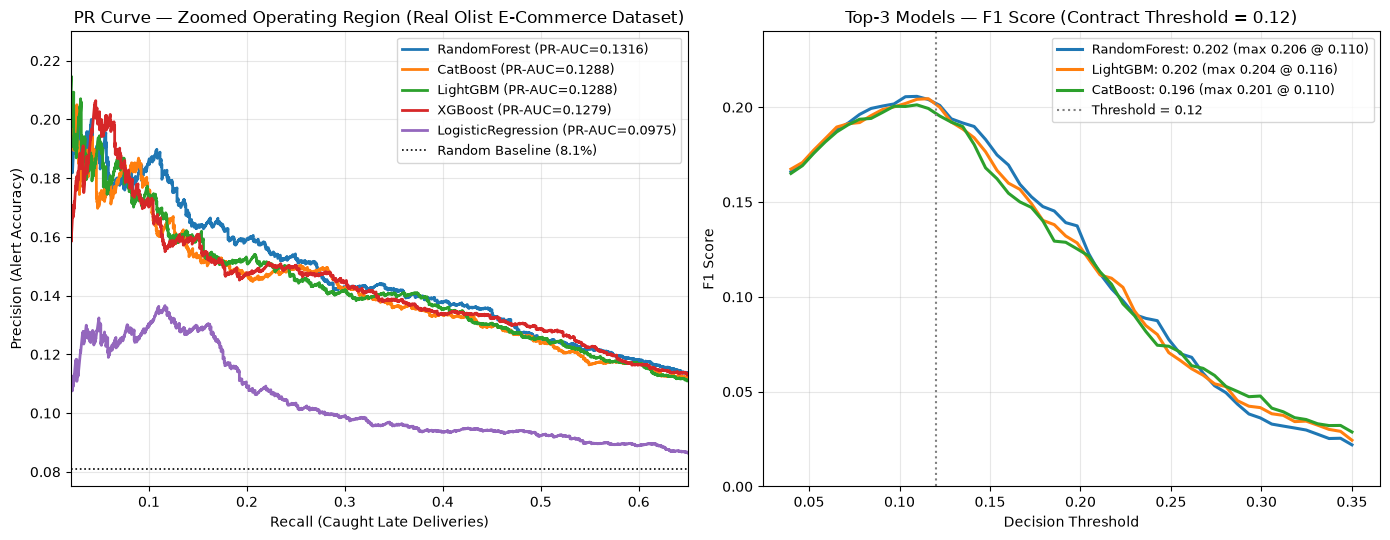

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Sort all models descending by PR-AUC
ranked = sorted(
    [(name, p, average_precision_score(y_test, p)) for name, p in probs.items()],
    key=lambda x: x[2],
    reverse=True,
)

# Left: Zoomed Precision-Recall Curve (legend sorted by PR-AUC)
base_rate = y_test.mean()
for name, p, ap in ranked:
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(rec, prec, lw=2, label=f"{name} (PR-AUC={ap:.4f})")

axes[0].axhline(base_rate, color="black", linestyle=":", lw=1.2, label=f"Random Baseline ({base_rate:.1%})")
axes[0].set_title(f"PR Curve — Zoomed Operating Region ({dataset_label})")
axes[0].set_xlabel("Recall (Caught Late Deliveries)")
axes[0].set_ylabel("Precision (Alert Accuracy)")
axes[0].set_xlim(0.02, 0.65)
axes[0].set_ylim(0.075, 0.23)
axes[0].legend(loc="upper right", fontsize=9)
axes[0].grid(alpha=0.3)

# Right: Top-3 Models F1 Threshold Tuning Comparison (sorted by F1 at contract threshold)
thresholds = np.linspace(0.04, 0.35, 50)
t_contract = contract["threshold"]

top3 = sorted(
    ranked[:3],
    key=lambda x: f1_score(y_test, x[1] >= t_contract, zero_division=0),
    reverse=True,
)

for name, p, _ in top3:
    f1s = [f1_score(y_test, p >= th, zero_division=0) for th in thresholds]
    f1_at_t = f1_score(y_test, p >= t_contract, zero_division=0)
    peak_idx = int(np.argmax(f1s))
    axes[1].plot(
        thresholds,
        f1s,
        lw=2.2,
        label=f"{name}: {f1_at_t:.3f} (max {f1s[peak_idx]:.3f} @ {thresholds[peak_idx]:.3f})",
    )

axes[1].axvline(t_contract, color="gray", linestyle=":", lw=1.5, label=f"Threshold = {t_contract}")
axes[1].set_title(f"Top-3 Models — F1 Score (Contract Threshold = {t_contract})")
axes[1].set_xlabel("Decision Threshold")
axes[1].set_ylabel("F1 Score")
axes[1].set_ylim(0.0, 0.24)
axes[1].legend(loc="upper right", fontsize=9)
axes[1].grid(alpha=0.3)

plt.tight_layout()
out_img = ARTIFACTS_DIR / "pr_curve_threshold.png"
plt.savefig(out_img, dpi=150)
print(f"Saved chart to {out_img}")
plt.show()

In [4]:
# Business Cost Simulator (Top 3 models):
# False Positive (unnecessary carrier reroute = $2) vs False Negative (late SLA refund/churn = $15)
COST_FP, COST_FN = 2.0, 15.0

summary_rows = []
for name, p, _ in ranked[:3]:
    best = None
    for th in thresholds:
        preds = (p >= th).astype(int)
        fp = int(((preds == 1) & (y_test == 0)).sum())
        fn = int(((preds == 0) & (y_test == 1)).sum())
        total_cost = fp * COST_FP + fn * COST_FN
        if best is None or total_cost < best["total_cost_usd"]:
            best = {
                "Model": name,
                "best_threshold": round(float(th), 3),
                "FP": fp,
                "FN": fn,
                "total_cost_usd": total_cost,
            }
    summary_rows.append(best)

cost_summary = pd.DataFrame(summary_rows).sort_values("total_cost_usd")
cost_summary

,Model,best_threshold,FP,FN,total_cost_usd
0,RandomForest,0.116,3611,968,21742.0
2,LightGBM,0.116,3687,958,21744.0
1,CatBoost,0.135,2364,1144,21888.0
